# cog-SUP - Basic and Advanced Methods in Neuroimaging: hands on EEG
## Preprocessing and classification of single-trial EEG

__Content creator:__ André R. Zarza Tapia, INCC (UMR 8002), Université Paris Cité

This notebook uses the **MNE-Python sample dataset** ([Gramfort et al., 2013](https://doi.org/10.3389/fnins.2013.00267)). One participant, recorded in Boston with a VectorView MEG/EEG system, received brief tones in the left or right ear and checkerboards in the left or right visual hemifield. MEG and EEG were recorded together.

**The two files of this TD** (stored in the course repository, the set-up cell below downloads them):

| File | Content | Used in |
|---|---|---|
| `sample_audvis_eeg_raw.fif` | a **30 s snippet** with all sensors: MEG + EEG + EOG + triggers | Part 1.1 and 1.2 (to see what MEG and EEG look like) |
| `sample_audvis_eeg_eog_stim_raw.fif` | the **whole recording** (about 4.6 min), only EEG + EOG + triggers | from Part 1.3 to the end |

It is the same recording: the snippet is the beginning of the long file, and we will check it. The MEG is only here to be looked at; **all the analyses of this TD are done on the EEG** (60 electrodes).

**Plan (about 3 hours)**
- **Part 1** - Know your data: MEG and EEG sensors, then the EEG file, events, raw signal. *Goal: know what you have before touching it.*
- **Part 2** - Preprocessing: spectrum, band-pass and notch filters, bad channels, ICA, re-referencing, epoching. *Goal: clean single trials, understanding what each step can damage.*
- **Part 3** - What do the evoked responses (ERPs) look like? *Goal: check that the data contain the expected responses, and set expectations for Part 4.*
- **Part 4** - Classification (decoding): from one time point to time-resolved decoding, cross-validation, comparison with mass-univariate tests, data leakage. Section 4.8 is a bonus. *Goal: measure how much information, and when.*
- **Part 5** - Wrap-up. *Goal: critical view of the whole pipeline.*

Same conventions as the MRI session: execute a cell with SHIFT+ENTER, run the cells in order, and answer the questions (labelled **Qx-y**) in a text cell below each of them. Some questions refer to earlier ones (for example "see Q1-4"): go back to your answer.
Figures are static in Colab: where you would scroll in an interactive window, we choose the window with `start=` and `duration=`.

---
# First steps
## Set-up the environment

In [ ]:
!pip install -q mne

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import mne

%matplotlib inline
mne.set_log_level("WARNING")
print("MNE version:", mne.__version__)

MNE version: 1.13.2


Download the two data files from the course repository (they are stored in it, nothing to download from elsewhere).

In [ ]:
if not os.path.isdir("CogSup_TimeSeriesTD_2026"):
    !git clone -q https://github.com/azarzatapia/CogSup_TimeSeriesTD_2026.git

def find(name):
    hits = glob.glob(f"**/{name}", recursive=True) + glob.glob(f"/content/**/{name}", recursive=True)
    assert hits, f"{name} not found: check that the repository was cloned"
    return hits[0]

file_meg_eeg = find("sample_audvis_eeg_raw.fif")
file_eeg     = find("sample_audvis_eeg_eog_stim_raw.fif")
for f in (file_meg_eeg, file_eeg):
    print(f"{f}: {os.path.getsize(f) / 1e6:.0f} MB")

---
# Part 1: Know your data  (about 25 min)
Before any processing, we need to know what we have: how the data are stored, which sensors, which events. Most preprocessing mistakes come from skipping this step.

> **What this part is for**
> - **Goal**: build an accurate picture of the recording before touching it.
> - **You will**: compare MEG and EEG sensors, read the acquisition information (sampling rate, hardware filters, units), look at the events and their order, and spot a bad channel and a blink in the raw signal.
> - **You should leave with**: the facts about the data that you will need later (a fixed order of conditions, intervals between stimuli, a flat channel, hardware filters already applied).

## 1.1 A first look: MEG and EEG in a 30 s snippet
`Raw` is the MNE object for continuous data. The snippet contains **all** the sensors of the recording, so we can compare MEG and EEG.

In [3]:
raw_meg = mne.io.read_raw_fif(file_meg_eeg, preload=True)
print(raw_meg.info)

<Info | 21 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
>


In [5]:
n_grad = len(mne.pick_types(raw_meg.info, meg="grad", exclude=()))
n_mag  = len(mne.pick_types(raw_meg.info, meg="mag", exclude=()))
n_eeg  = len(mne.pick_types(raw_meg.info, eeg=True, exclude=()))
n_eog  = len(mne.pick_types(raw_meg.info, eog=True, exclude=()))
n_stim = len(mne.pick_types(raw_meg.info, stim=True, exclude=()))

print(f"Sampling rate  : {raw_meg.info['sfreq']:.1f} Hz")
print(f"Duration       : {raw_meg.times[-1]:.0f} s")
print(f"Total channels : {raw_meg.info['nchan']}")
print(f"  - Gradiometers : {n_grad}")
print(f"  - Magnetometers: {n_mag}")
print(f"  - EEG channels : {n_eeg}")
print(f"  - EOG channels : {n_eog}")
print(f"  - Stim channels: {n_stim}")
print(f"Marked as bad  : {raw_meg.info['bads']}")
print(f"Hardware high-pass / low-pass : {raw_meg.info['highpass']:.1f} Hz / {raw_meg.info['lowpass']:.1f} Hz")
print(f"Line frequency : {raw_meg.info['line_freq']}")
print(f"Data shape     : {raw_meg.get_data().shape}   (channels x samples)")

Sampling rate  : 600.6 Hz
Duration       : 30 s
Total channels : 376
  - Gradiometers : 204
  - Magnetometers: 102
  - EEG channels : 60
  - EOG channels : 1
  - Stim channels: 9
Marked as bad  : ['MEG 2443', 'EEG 053']
Hardware high-pass / low-pass : 0.1 Hz / 172.2 Hz
Line frequency : None
Data shape     : (376, 18019)   (channels x samples)


**Q1-1: What is the sampling rate of this recording? Based on this, what is the highest frequency (Nyquist frequency) that the data can represent without distortion?**
*(Hint: can this dataset capture high-gamma brain oscillations, which occur around 80-150 Hz?)*

**Q1-2: Look at the data shape printed above. How many time points (samples) were recorded per channel? Verify that this number matches what you expect from the duration and the sampling rate.**
*(Formula: expected samples = duration (s) x sampling rate (Hz).)*

**Q1-3: How many different types of channels are present in this recording, and what physical or experimental signal does each type capture?**
*(Hint: consider why a neuroimaging session records MEG, EEG, EOG and stimulus channels all at once.)*

**Q1-4: The file reports a "highpass" and a "lowpass" value, and a line frequency of `None`. What do the first two correspond to (the data has not been touched by us)? Does `None` mean that there is no power-line noise in the recording? Keep your answer: it will matter for the filtering of Part 2.**

The MEG and the EEG are not measured in the same units. The cell below gives the typical amplitude (standard deviation over the 30 s) of each channel type, with its own unit.

In [6]:
units = {"mag": ("fT", 1e15), "grad": ("fT/cm", 1e13), "eeg": ("µV", 1e6), "eog": ("µV", 1e6)}
for ch_type, (unit, scale) in units.items():
    data = raw_meg.get_data(picks=ch_type, exclude="bads")
    print(f"{ch_type:5s}: {data.shape[0]:3d} channels, median standard deviation = {np.median(data.std(axis=1)) * scale:7.1f} {unit}")

mag  : 102 channels, median standard deviation =   624.0 fT
grad : 203 channels, median standard deviation =    60.8 fT/cm
eeg  :  59 channels, median standard deviation =    12.0 µV
eog  :   1 channels, median standard deviation =    34.4 µV


**Q1-5: Is the EEG amplitude what you expected for scalp EEG? Why is EEG so much smaller than, for example, an electrocardiogram (millivolts)? The magnetometers are in femtotesla (1 fT = 10^-15 T) while the Earth's magnetic field is about 50 µT: how many times larger is it than the MEG signal, and what does this imply for the recording room?**

## 1.2 Where are the sensors?
The position of each sensor is stored in the file. EEG electrodes sit on the scalp, MEG sensors are in a helmet around the head.

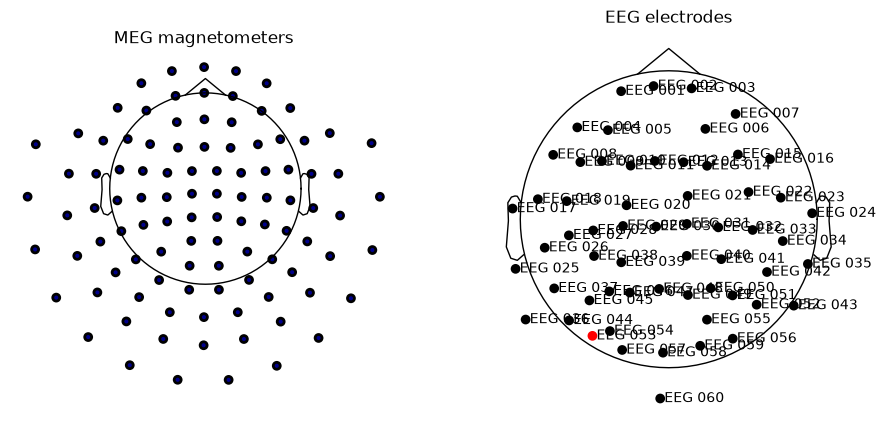

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
raw_meg.plot_sensors(kind="topomap", ch_type="mag", axes=axes[0], show=False)
axes[0].set_title("MEG magnetometers")
raw_meg.plot_sensors(kind="topomap", ch_type="eeg", show_names=True, axes=axes[1], show=False)
axes[1].set_title("EEG electrodes");

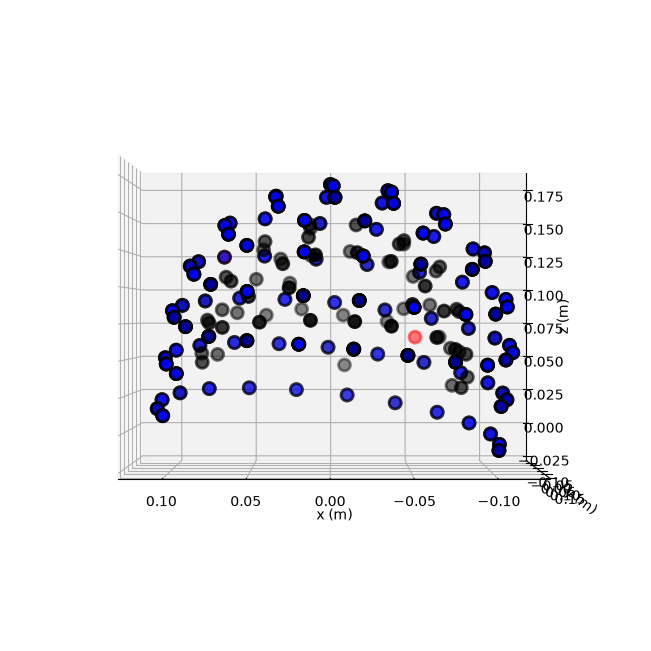

In [8]:
# all the sensors in 3D: MEG in blue, EEG in black, bad channels in red
raw_meg.plot_sensors(kind="3d", ch_type="all");

**Q1-6: On the EEG layout, where are the nose and the ears? Which channel is shown in red (marked as bad)? Why does the software need to know the position of each electrode (think about topographies and about replacing a bad channel)? In the 3D view, how do the MEG sensors and the EEG electrodes differ in their distance to the head?**

Now the same 5 seconds in MEG and in EEG: three frontal magnetometers, two frontal EEG channels and the EOG channel. The 5 seconds contain a large eye blink.

In [9]:
# blinks detected on the EOG channel
eog_events = mne.preprocessing.find_eog_events(raw_meg, ch_name="EOG 061")
blink_times = (eog_events[:, 0] - raw_meg.first_samp) / raw_meg.info["sfreq"]          # seconds from the start of the file
print(f"{len(blink_times)} blinks detected in the 30 s snippet, at t = {np.round(blink_times, 1)} s")

# we look at the isolated blink around 14.5 s (no other blink within 5 s)
t_blink = blink_times[np.argmin(np.abs(blink_times - 14.5))]

# the three most frontal magnetometers
mags = mne.pick_types(raw_meg.info, meg="mag", exclude=())
y_pos = np.array([raw_meg.info["chs"][i]["loc"][1] for i in mags])
frontal_mags = [raw_meg.ch_names[mags[i]] for i in np.argsort(y_pos)[-3:]]

raw_meg.plot(picks=frontal_mags + ["EEG 001", "EEG 002", "EOG 061"], start=t_blink - 2, duration=5,
             scalings=dict(mag=2e-12, eeg=50e-6, eog=300e-6), title="Same 5 s: MEG (blue), EEG and EOG");

4 blinks detected in the 30 s snippet, at t = [ 0.5  2.3  3.7 14.5] s


/opt/homebrew/Caskroom/miniforge/base/envs/mne/lib/python3.14/site-packages/mne_qt_browser/_utils.py:36: RuntimeWarning: libpyside: Failed to disconnect (None) from signal "triggered()".
  sig.disconnect()
/opt/homebrew/Caskroom/miniforge/base/envs/mne/lib/python3.14/site-packages/mne_qt_browser/_utils.py:36: RuntimeWarning: libpyside: Failed to disconnect (None) from signal "triggered()".
  sig.disconnect()
/opt/homebrew/Caskroom/miniforge/base/envs/mne/lib/python3.14/site-packages/mne_qt_browser/_utils.py:36: RuntimeWarning: libpyside: Failed to disconnect (None) from signal "triggered()".
  sig.disconnect()
/opt/homebrew/Caskroom/miniforge/base/envs/mne/lib/python3.14/site-packages/mne_qt_browser/_utils.py:36: RuntimeWarning: libpyside: Failed to disconnect (None) from signal "triggered()".
  sig.disconnect()
/opt/homebrew/Caskroom/miniforge/base/envs/mne/lib/python3.14/site-packages/mne_qt_browser/_utils.py:36: RuntimeWarning: libpyside: Failed to disconnect (None) from signal "tri

In [10]:
# a second, regular artifact: detect it from a frontal magnetometer
ecg_events, _, heart_rate = mne.preprocessing.find_ecg_events(raw_meg, ch_name=frontal_mags[0])
print(f"{len(ecg_events)} events detected in 30 s, i.e. {heart_rate:.0f} per minute")

29 events detected in 30 s, i.e. 58 per minute


**Q1-7: Look at the plot. (a) Which channels show the large slow deflection that goes with the EOG? (b) Which channels show the small regular sharp deflections, and at what rate (the cell below the plot detects them)? What is the biological source of each of the two? (c) Which of these two artifacts matters for EEG, and which for MEG? What does this tell you about the need for preprocessing in both modalities?**

## 1.3 The EEG file
In the rest of the TD we use **EEG only**. We now load the second file: the same recording, restricted to the EEG, EOG and trigger channels, and **not cropped**. From here on, `raw` is this file.

In [11]:
raw = mne.io.read_raw_fif(file_eeg, preload=True)
print(raw)
print(f"Duration: {raw.times[-1]:.0f} s (the snippet had {raw_meg.times[-1]:.0f} s)")
ch_types, n_per_type = np.unique(raw.get_channel_types(), return_counts=True)
print("Channel types:", ", ".join(f"{int(n)} {t}" for t, n in zip(ch_types, n_per_type)))
print(f"Marked as bad: {raw.info['bads']}   (in the snippet: {raw_meg.info['bads']})")

# is the snippet really the beginning of the same recording?
n = raw_meg.n_times
same = np.allclose(raw_meg.get_data(picks="eeg"), raw.get_data(picks="eeg")[:, :n])
print(f"EEG data of the snippet identical to the first {raw_meg.times[-1]:.0f} s of this file: {same}")

<Raw | sample_audvis_eeg_eog_stim_raw.fif, 70 x 166800 (277.7 s), ~92.0 MiB, data loaded>
Duration: 278 s (the snippet had 30 s)
Channel types: 60 eeg, 1 eog, 9 stim
Marked as bad: ['EEG 053']   (in the snippet: ['MEG 2443', 'EEG 053'])
EEG data of the snippet identical to the first 30 s of this file: True


**Q1-8: Compare the two files (channel types, duration, bad channels). Why is only one channel still marked as bad here? Why can we use the 30 s snippet to learn about the EEG of the long file, and what could not be learned from it?**

Experimental events are stored on a trigger channel (`STI 014`) as numerical codes. We extract them and give names to the four codes of interest.

code  1: 72 events
code  2: 73 events
code  3: 73 events
code  4: 71 events
code  5: 15 events
code 32: 16 events

The first 24 event codes, in order:
[ 2  3  1  4  2  3  1  4  2  3  1  4  2  3  1  5  2 32  3  1  4  2  3  1]


/var/folders/ry/fy29vzdj4g93lnnzkp4k7p_h0000gn/T/ipykernel_22331/2082452310.py:12: RuntimeWarning: event 5 missing from event_id will be ignored
  mne.viz.plot_events(events, sfreq=raw.info["sfreq"], first_samp=raw.first_samp, event_id=event_id);
/var/folders/ry/fy29vzdj4g93lnnzkp4k7p_h0000gn/T/ipykernel_22331/2082452310.py:12: RuntimeWarning: event 32 missing from event_id will be ignored
  mne.viz.plot_events(events, sfreq=raw.info["sfreq"], first_samp=raw.first_samp, event_id=event_id);


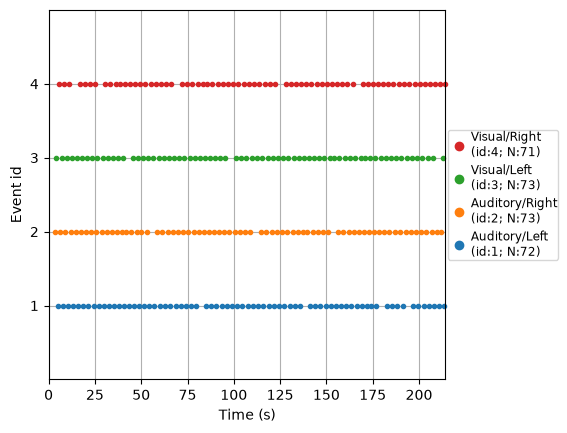

In [12]:
events = mne.find_events(raw, stim_channel="STI 014")      # array: (sample, 0, code)
event_id = {"Auditory/Left": 1, "Auditory/Right": 2, "Visual/Left": 3, "Visual/Right": 4}

codes, counts = np.unique(events[:, 2], return_counts=True)
for c, n in zip(codes, counts):
    print(f"code {c:>2}: {n} events")

print("\nThe first 24 event codes, in order:")
print(events[:24, 2])

# MNE warns that the codes not listed in event_id are ignored: this is expected
mne.viz.plot_events(events, sfreq=raw.info["sfreq"], first_samp=raw.first_samp, event_id=event_id);

**Q1-9: Which codes are present, and how many events of each? Which ones correspond to our four conditions? (The other two, 5 and 32, are not used in this TD.)**

**Q1-10: Look at the sequence of the first event codes. Is the order random? Describe the pattern. Then see the table below, which counts for each stimulus which stimulus came just before it.**

In [ ]:
# keep only the four stimulus codes, and count (previous stimulus -> current stimulus)
stim_ev = events[np.isin(events[:, 2], list(event_id.values()))]
table = np.zeros((4, 4), dtype=int)
for prev, cur in zip(stim_ev[:-1, 2], stim_ev[1:, 2]):
    table[prev - 1, cur - 1] += 1
short = {"Auditory/Left": "AL", "Auditory/Right": "AR", "Visual/Left": "VL", "Visual/Right": "VR"}      # A = auditory, V = visual, L = left, R = right
print("Number of times a stimulus (column) directly follows a stimulus (row):")
print(pd.DataFrame(table, index=[f"after {v}" for v in short.values()], columns=list(short.values())).to_string())

isi = np.diff(stim_ev[:, 0]) / raw.info["sfreq"]
print(f"\nInterval between consecutive stimuli: median {np.median(isi):.2f} s, min {isi.min():.2f} s, max {isi.max():.2f} s")

**Q1-11: What does the table tell you about the order of the conditions? Is the modality of a trial independent of the modality of the previous trial? Keep this in mind for the pre-stimulus period of the epochs (Part 2.7) and for the classification (Part 4).**

**Q1-12: Look at the intervals between consecutive stimuli. What does this tell you about the length of the epochs we can cut around each stimulus without overlap between trials?**

**Q1-13: Roughly how many trials do we have per condition? Why is the number of trials a critical parameter for ERPs, and even more for single-trial classification (anticipate Parts 3 and 4)? How many would the 30 s snippet have given?**

## 1.4 The raw signal
The EOG channel records the electrical activity of the eye. A blink is a large, brief deflection. We detect the blinks on the whole recording and look at the same blink as in Part 1.2, now in the EEG file.

In [ ]:
eog_events = mne.preprocessing.find_eog_events(raw, ch_name="EOG 061")
blink_times = (eog_events[:, 0] - raw.first_samp) / raw.info["sfreq"]       # seconds from the start of the file
print(f"{len(blink_times)} blinks detected = {len(blink_times) / (raw.times[-1] / 60):.1f} per minute")

# channels to display: the EOG, the bad channel(s), and the first 10 EEG channels
eeg_names = [raw.ch_names[i] for i in mne.pick_types(raw.info, eeg=True, exclude=())]
view_picks = ["EOG 061"] + raw.info["bads"] + eeg_names[:10]

raw.plot(picks=view_picks, start=t_blink - 2, duration=6, scalings=dict(eeg=50e-6, eog=300e-6),
         title="Raw data around a blink");

**Q1-14: Is the detected blink rate plausible? On the plot, which channels show the blink most strongly, and why those?**

**Q1-15: Look at the bad channel (grey). What is different about its signal compared with the other channels? Is it noisier or quieter?**

---
# Part 2: Preprocessing  (about 40 min)
Raw EEG is dominated by things we do not care about: slow drifts, line noise, blinks, noisy electrodes. Preprocessing reduces them **without distorting what we do care about**.

> **What this part is for**
> - **Goal**: turn continuous raw EEG into clean single-trial epochs that can be averaged (Part 3) or classified (Part 4).
> - **You will**: look at the spectrum, filter (band-pass and notch), find a bad channel, remove blinks with ICA, interpolate and re-reference, cut epochs and reject the worst ones.
> - **You should leave with**: an understanding of what each step removes **and what it can damage**, and a clean `epochs` object used in the rest of the TD.

The order of the steps matters:

1. Look at the spectrum
2. Filter (band-pass)
3. Notch filter (what it is, and why we do not use it here)
4. Detect bad channels
5. Remove blinks with ICA (fitted on a more strongly filtered copy)
6. Interpolate bad channels, re-reference to the average
7. Cut epochs, correct the baseline, reject the remaining bad trials

## 2.1 Look at the spectrum first

In [ ]:
# a small helper to draw spectra in colour: one line per channel, coloured from back (blue) to front (red) of the head;
# bad channels are drawn in thick black so that they are easy to spot
def plot_psd(r, ax, exclude_bads=True, title="", cmap="coolwarm"):
    sp = r.compute_psd(fmax=100, picks="eeg", exclude=() if not exclude_bads else "bads")
    power, freqs = sp.get_data(return_freqs=True)
    chs = [c for c in sp.ch_names]
    y = np.array([r.info["chs"][r.ch_names.index(c)]["loc"][1] for c in chs])      # front-back position of each electrode
    norm = plt.Normalize(y.min(), y.max())
    for p, c, yy in zip(power, chs, y):
        bad = c in r.info["bads"]
        ax.semilogy(freqs, p, color="k" if bad else plt.get_cmap(cmap)(norm(yy)), lw=2.2 if bad else 0.8, zorder=3 if bad else 2,
                    label=f"{c} (bad)" if bad else None)
    ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (V²/Hz)"); ax.set_title(title); ax.grid(alpha=0.3)
    if any(c in r.info["bads"] for c in chs): ax.legend(loc="upper right")
    return power, freqs

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_psd(raw, axes[0], exclude_bads=False, title="All EEG channels (bad channel in black)")
plot_psd(raw, axes[1], exclude_bads=True,  title="Bad channels excluded")
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=plt.Normalize(0, 1))
cb = fig.colorbar(sm, ax=axes, ticks=[0, 1], pad=0.02, fraction=0.03); cb.ax.set_yticklabels(["front", "back"])
plt.show()

In [ ]:
# size of the 60 Hz peak: power at 60 Hz relative to the neighbouring frequencies (55 and 65 Hz), median over channels
def line_peak(r, ch_type):
    sp = r.compute_psd(fmax=100, picks=ch_type, exclude="bads", n_fft=2048)
    p, f = sp.get_data(return_freqs=True)
    k = np.argmin(abs(f - 60)); k_nb = [np.argmin(abs(f - 55)), np.argmin(abs(f - 65))]
    return np.median(p[:, k] / p[:, k_nb].mean(axis=1))

print(f"60 Hz peak in the 30 s snippet: MEG magnetometers x{line_peak(raw_meg, 'mag'):.1f}, EEG x{line_peak(raw_meg, 'eeg'):.1f}")
print(f"60 Hz peak in the whole EEG recording (good channels): x{line_peak(raw, 'eeg'):.1f}")

**Q2-1: Describe the spectrum of the good channels (right panel): what is the general trend with frequency? Is there a clear peak in a particular band (for example around 10 Hz)? Is there any narrow peak?**

**Q2-2: In the left panel, one channel shows a very narrow peak at 60 Hz (and a few others). Where does 60 Hz come from? What would you expect in a recording made in Paris? The file said that the line frequency is `None` (Q1-4): how could you have found it from the data? Is the peak also visible in the good EEG channels? (For comparison, look back at the MEG snippet of Part 1.1: the cell below computes the size of the 60 Hz peak in MEG magnetometers and in EEG.)**

**Q2-3: Compare the two panels. How does the bad channel stand out in the spectrum (overall level, and shape)? Is it what you expected from the raw plot of Part 1.4 (Q1-15)? Why would a channel that records almost no brain signal show a 60 Hz peak more clearly than the others?**

## 2.2 Filtering
We apply a band-pass filter, **0.1-40 Hz**: the high-pass removes very slow drifts and the constant offset of each channel, the low-pass removes muscle activity and the line noise. Note that the acquisition system already applied a hardware high-pass and low-pass (Q1-4). `raw.filter` modifies the object it is called on, so we work on `raw.copy()`: the original `raw` stays untouched.

In [ ]:
raw_f = raw.copy().filter(l_freq=0.1, h_freq=40.0, picks=["eeg", "eog"], fir_design="firwin")

fig, ax = plt.subplots(figsize=(7, 4))
for r, label, col in [(raw, "before", "tab:blue"), (raw_f, "after band-pass 0.1-40 Hz", "tab:red")]:
    psd = r.compute_psd(fmax=100, picks="eeg", exclude="bads")
    power, freqs = psd.get_data(return_freqs=True)
    ax.semilogy(freqs, power.mean(axis=0), color=col, lw=2, label=label)
ax.axvspan(40, 100, color="tab:red", alpha=0.07, label="removed by the 40 Hz low-pass")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (V²/Hz), mean over channels"); ax.grid(alpha=0.3); ax.legend();

In [ ]:
# the same channel in the time domain, 30 seconds
ch = "EEG 021"
sl = slice(int(60 * raw.info["sfreq"]), int(90 * raw.info["sfreq"]))
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(raw.times[sl], raw.get_data(picks=ch)[0, sl] * 1e6, label="raw")
ax.plot(raw_f.times[sl], raw_f.get_data(picks=ch)[0, sl] * 1e6, label="filtered 0.1-40 Hz")
ax.set_xlabel("Time (s)"); ax.set_ylabel("µV"); ax.set_title(ch); ax.legend();

**Q2-4: What changed in the spectrum above 40 Hz? We did not use a notch filter: was one needed for these EEG channels (Q2-2)? When would you need one? Given what you found about the hardware filters (Q1-4), do you expect our 0.1 Hz high-pass to change the spectrum much?**

**Q2-5: What did the high-pass change in the time-domain plot (compare the level around which each trace fluctuates)? What kind of artifact does a slow drift correspond to?**

The filter used here is *zero-phase*: it is applied so that it does not shift the signal in time, which means it also acts on the signal **before** an event.

**Q2-6: Why is a zero-phase filter convenient for ERPs? Can you think of a risk when we later look at the pre-stimulus period (keep this in mind for Parts 3.4 and 4)?**

## 2.3 Notch filter: removing the mains
A **notch filter** is a band-stop filter with a very narrow stop band: it removes one frequency (here 60 Hz, the mains in North America; 50 Hz in Europe) and leaves everything else almost untouched, as opposed to the low-pass of 2.2, which removes **everything** above 40 Hz. The mains also leaks into the harmonics (120 Hz, 180 Hz, ...), so a notch is usually applied at the fundamental and its multiples: `raw.notch_filter(freqs=[60, 120])`.

When is it useful?
- when you want to keep frequencies **above** the line frequency (gamma activity), where a low-pass cannot be used;
- when the line peak is **large** compared with the neighbouring frequencies, as in MEG.

Its price is a "hole" in the spectrum (and some ringing in the time domain), so it should not be used when it is not needed. We test it on two kinds of data: the MEG magnetometers of the snippet, where the line noise is strong, and the EEG of the long recording. Both are band-passed at 0.1-150 Hz first (so that we are not looking at the effect of the 40 Hz low-pass).

In [ ]:
# band-pass WITHOUT the 40 Hz low-pass, then notch at 60 and 120 Hz
def notched(r, picks):
    r1 = r.copy().pick(picks).filter(l_freq=0.1, h_freq=150.0, fir_design="firwin")
    r2 = r1.copy().notch_filter(freqs=[60, 120], picks=picks)
    return r1, r2

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (r, picks, name) in zip(axes, [(raw_meg, "mag", "MEG magnetometers (30 s snippet)"), (raw, "eeg", "EEG (whole recording, good channels)")]):
    r1, r2 = notched(r, picks)
    for rr, label, col in [(r1, "band-pass only", "tab:blue"), (r2, "band-pass + notch (60, 120 Hz)", "tab:red")]:
        sp = rr.compute_psd(fmax=150, picks=picks, exclude="bads", n_fft=2048)
        p, f = sp.get_data(return_freqs=True)
        ax.semilogy(f, p.mean(axis=0), color=col, lw=1.8, label=label)
    for fl in (60, 120): ax.axvline(fl, color="gray", ls=":", lw=1)
    ax.set_title(name); ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power, mean over channels"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()

In [ ]:
# zoom on the notch: the line is replaced by a narrow hole, the rest of the spectrum is unchanged (EEG, 50-70 Hz)
r1, r2 = notched(raw, "eeg")
fig, ax = plt.subplots(figsize=(7, 3.5))
for rr, label, col in [(r1, "band-pass only", "tab:blue"), (r2, "band-pass + notch", "tab:red")]:
    sp = rr.compute_psd(fmin=50, fmax=70, picks="eeg", exclude="bads", n_fft=4096)
    p, f = sp.get_data(return_freqs=True)
    ax.semilogy(f, p.mean(axis=0), color=col, lw=2, label=label)
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power, mean over channels"); ax.grid(alpha=0.3); ax.legend();

**Q2-7: Compare the two panels. In which data does the notch make a visible difference, and in which does it barely change anything? Relate this to the size of the 60 Hz peak you measured in 2.1 (Q2-2). In the zoomed plot, how wide is the "hole" made by the notch?**

**Q2-8: In this TD, we do not apply a notch filter. Give two reasons why (think about the 40 Hz low-pass and about what a notch costs). Which frequencies would you notch if this recording had been made in Paris? In which kind of analysis would you not be able to avoid it?**

## 2.4 Bad channels
A bad channel is an electrode with poor contact or a broken connection. Here one is already marked in the file, but how would you find it yourself? A simple criterion is the **standard deviation** of each channel, compared with the other channels.

In [ ]:
data_eeg = raw_f.get_data(picks="eeg")                     # bad channels are included here
ch_std = data_eeg.std(axis=1) * 1e6
robust_z = (ch_std - np.median(ch_std)) / (1.4826 * np.median(np.abs(ch_std - np.median(ch_std))))

colors = ["tab:red" if n in raw_f.info["bads"] else "tab:blue" for n in eeg_names]
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(range(len(ch_std)), ch_std, color=colors)
ax.set_xlabel("EEG channel index"); ax.set_ylabel("Standard deviation (µV)")
ax.set_title("Red = marked as bad in the file")
print("Channels with |robust z| > 3.5:", [n for n, z in zip(eeg_names, robust_z) if abs(z) > 3.5])

**Q2-9: Does this criterion flag the channel that is marked as bad? Does it flag others? Are the other flagged channels too noisy or too quiet, where are they on the head (see the sensor layout, Q1-6) and what could explain it (think of Q1-14)? What other criteria could you use (flat channels, correlation with neighbours, the spectrum)?**

We do **not** interpolate yet: the bad channel is first left out of the ICA (next section), then interpolated.

## 2.5 Blinks with ICA
Independent Component Analysis (ICA) decomposes the multichannel recording into statistically independent sources. Some of them are brain rhythms, some are artifacts such as blinks. We remove the source(s) that look like blinks and reconstruct the data without them.

Two practical points: (1) ICA works much better on data that has been **high-passed at 1 Hz** (slow drifts violate its assumptions), so we fit it on a separate copy; (2) the resulting unmixing is then applied to our less aggressively filtered data.

In [ ]:
raw_ica = raw.copy().filter(l_freq=1.0, h_freq=40.0, picks=["eeg", "eog"], fir_design="firwin")

ica = mne.preprocessing.ICA(n_components=15, random_state=97, max_iter="auto")
ica.fit(raw_ica, decim=3)             # decim=3: fit on every 3rd sample (faster); the bad channel is left out automatically
print(ica)
ica.plot_components();

In [ ]:
# automatically find the components that correlate with the EOG channel
eog_idx, eog_scores = ica.find_bads_eog(raw_ica, ch_name="EOG 061")
eog_idx = [int(i) for i in eog_idx]
print("Components flagged as blinks:", eog_idx)
ica.plot_scores(eog_scores, exclude=eog_idx);

# time course of the first components around the blink we have been looking at
ica.plot_sources(raw_ica, picks=list(range(6)), start=t_blink - 2, stop=t_blink + 4);

**Q2-10: What does an ICA component represent (a topography and a time course)? What assumption about the sources allows ICA to separate a blink from the brain activity?**

**Q2-11: Look at the topographies. Which component(s) look like blinks, and why do they have this spatial distribution (compare with the channels that showed the blink in Q1-14)? Does it agree with the automatic detection? Some other components also have a frontal or lateral-frontal topography: what could they be, and why did the EOG correlation not flag them (the EOG is a single channel)?**

**Q2-12: Why do we fit ICA on a 1 Hz high-pass copy, but apply it to the 0.1 Hz data? (You will see in Part 3.4 how much the two high-pass settings differ on the ERP, Q3-7.)**

Now we remove the flagged component(s) from the 0.1-40 Hz data and compare before / after around the same blink.

In [ ]:
ica.exclude = eog_idx            # you can also choose components by hand, e.g. ica.exclude = [0]
raw_clean = raw_f.copy()
ica.apply(raw_clean)

raw_f.plot(picks=view_picks, start=t_blink - 2, duration=6, scalings=dict(eeg=50e-6, eog=300e-6), title="Before ICA");
raw_clean.plot(picks=view_picks, start=t_blink - 2, duration=6, scalings=dict(eeg=50e-6, eog=300e-6), title="After ICA");

**Q2-13: Are the blinks gone on the EEG channels? And on the EOG channel? Do you see other changes in the signal? What is the risk of removing a component?**

## 2.6 Interpolate the bad channel and re-reference
EEG always measures a potential *difference* with respect to a reference. We re-reference to the **average of all electrodes**, which needs a complete set of good channels: so we first replace the bad channel by an interpolation of its neighbours (this is why we needed the electrode positions, Q1-6).

In [ ]:
def rank_of(r, tol=1e-10):
    # number of linearly independent EEG signals: singular values that are not numerically zero
    s = np.linalg.svd(r.get_data(picks="eeg"), compute_uv=False)
    return int((s / s[0] > tol).sum())

n_eeg = len(mne.pick_types(raw_clean.info, eeg=True, exclude=()))

raw_clean.interpolate_bads(reset_bads=True)
print("Bad channels left:", raw_clean.info["bads"])
print(f"Rank after interpolation      : {rank_of(raw_clean)}   ({n_eeg} EEG channels)")

raw_clean.set_eeg_reference("average")
eeg_clean = raw_clean.get_data(picks="eeg")
print(f"Largest absolute value of the mean across channels: {np.abs(eeg_clean.mean(axis=0)).max():.2e} V")
print(f"Rank after average reference  : {rank_of(raw_clean)}   ({n_eeg} EEG channels)")

**Q2-14: Why do we interpolate the bad channel after ICA rather than before, and why was it left out of the ICA fit? What new information does an interpolated channel contain?**

**Q2-15: What does the average reference do to the signals? What does the first printed check show?**

**Q2-16: The rank is smaller than the number of channels. Which of the two steps lowered it, and why (think of what an interpolated channel and an average-referenced channel are, in terms of the other channels)? Keep this in mind for the classifier of Part 4: what could go wrong with a method that inverts the covariance matrix of the channels?**

## 2.7 Epoching
We cut the continuous signal into epochs around each stimulus (-200 to +500 ms), subtract the mean of the pre-stimulus period (**baseline**), and drop the epochs whose peak-to-peak amplitude exceeds 100 µV. We also **decimate** (keep one sample out of 4): the data was low-passed at 40 Hz, so a sampling rate of about 150 Hz is sufficient and makes the analyses of Part 4 faster.

In [ ]:
tmin, tmax = -0.2, 0.5
reject = dict(eeg=100e-6)                    # peak-to-peak threshold: 100 µV

epochs = mne.Epochs(raw_clean, events, event_id=event_id, tmin=tmin, tmax=tmax,
                    baseline=(None, 0), reject=reject, decim=4, preload=True)
print(epochs)
print(f"New sampling rate: {epochs.info['sfreq']:.1f} Hz")
epochs.plot_drop_log();

In [ ]:
# the same without ICA, to see the effect of artifact removal on the number of rejected trials
epochs_noica = mne.Epochs(raw_f, events, event_id=event_id, tmin=tmin, tmax=tmax,
                          baseline=(None, 0), reject=reject, decim=4, preload=True)
n_total = np.isin(events[:, 2], list(event_id.values())).sum()
print(f"Epochs kept: {len(epochs)} / {n_total} with ICA, {len(epochs_noica)} / {n_total} without ICA")

**Q2-17: What does the baseline correction do, and what assumption does it rely on? Is this assumption satisfied here, given the interval between stimuli (Q1-12) and the order of the conditions (Q1-11)? What is present in the 200 ms before a stimulus?**

**Q2-18: How many trials remain in each condition? Compare with and without ICA and explain the difference. Change the threshold (for example 50 µV and 150 µV) and rerun: what changes?**

**Q2-19: What is the sampling rate after decimation? Why is it safe to decimate here? What would go wrong if we decimated data that had not been low-pass filtered?**

**Q2-20: Epochs are rejected based on their amplitude only. Could this introduce a difference between conditions? Why would it matter for classification?**

---
# Part 3: What do the evoked responses look like?  (about 20 min)
Averaging the epochs of one condition gives the **event-related potential** (ERP): activity that is time-locked to the stimulus survives, background activity averages out.

> **What this part is for**
> - **Goal**: check that the preprocessed data contain what we expect (an auditory response, a visual response) before trying to classify anything.
> - **You will**: plot the average response of each condition, map it over the scalp, compare it with single trials, and see what a too strong high-pass filter does.
> - **You should leave with**: a first idea of when and where the conditions differ (it will tell you what to expect from the classifier in Part 4), and of how much noise there is in a single trial.

## 3.1 Averages

In [ ]:
evokeds = {cond: epochs[cond].average() for cond in event_id}

evokeds["Auditory/Left"].plot(picks="eeg", spatial_colors=True, gfp=True, titles="Auditory/Left");
evokeds["Visual/Left"].plot(picks="eeg", spatial_colors=True, gfp=True, titles="Visual/Left");

**Q3-1: Describe the auditory and the visual responses: at what latencies do you see the main deflections? Are the two responses similar?**

**Q3-2: The lower panel shows the Global Field Power (GFP, the standard deviation across channels at each time). What does it tell you that a single channel does not?**

## 3.2 Topographies

In [ ]:
times = [0.05, 0.1, 0.15, 0.2, 0.3]
for cond in ["Auditory/Left", "Visual/Left"]:
    fig = evokeds[cond].plot_topomap(times=times, ch_type="eeg", show=False)
    fig.suptitle(cond)

# left minus right, within each modality
diff_aud = mne.combine_evoked([evokeds["Auditory/Left"], evokeds["Auditory/Right"]], weights=[1, -1])
diff_vis = mne.combine_evoked([evokeds["Visual/Left"], evokeds["Visual/Right"]], weights=[1, -1])
for diff, title in [(diff_aud, "Auditory: left - right"), (diff_vis, "Visual: left - right")]:
    fig = diff.plot_topomap(times=[0.1, 0.15, 0.2], ch_type="eeg", show=False)
    fig.suptitle(title)

**Q3-3: Compare the auditory and the visual topographies. Where is each response strongest? Is it what you expect from the underlying cortical areas?**

**Q3-4: In the left - right maps, do you see a lateralised pattern? Is it the same for auditory and visual stimuli?**

**Q3-5: Make a prediction, and write it down: which classification will be easier in Part 4, *auditory vs visual* or *left vs right*? Why?**

## 3.3 Single trials
The ERP is an average. A classifier will have to work on **single trials**.

In [ ]:
ch = "EEG 021"
single = epochs["Auditory/Left"].get_data(picks=ch)[:, 0, :] * 1e6          # (n_trials, n_times), in µV

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(epochs.times, single[:8].T, color="grey", alpha=0.6, lw=0.8)
ax.plot(epochs.times, single.mean(axis=0), color="k", lw=2.5, label=f"average of {len(single)} trials")
ax.axvline(0, color="k", ls=":"); ax.set_xlabel("Time (s)"); ax.set_ylabel("µV"); ax.set_title(f"{ch}, Auditory/Left: 8 single trials"); ax.legend();

**Q3-6: Compare single trials and the average. What does this imply for the signal-to-noise ratio of single-trial classification? How does the noise in an average decrease with the number of trials (Q1-13)?**

## 3.4 Break it: what a too strong high-pass filter does
The only difference between the three curves below is the high-pass cutoff (the same pipeline otherwise: no ICA, no re-reference, to isolate the effect of the filter).

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
for hp in [0.1, 1.0, 5.0]:
    r = raw.copy().filter(l_freq=hp, h_freq=40.0, picks=["eeg", "eog"], fir_design="firwin")
    e = mne.Epochs(r, events, event_id=event_id, tmin=tmin, tmax=tmax, baseline=(None, 0), decim=4, preload=True)
    ev = e["Auditory/Left"].average()
    ax.plot(ev.times, ev.get_data(picks="EEG 021")[0] * 1e6, label=f"high-pass {hp} Hz")
ax.axvline(0, color="k", ls=":"); ax.set_xlabel("Time (s)"); ax.set_ylabel("µV"); ax.set_title("EEG 021, Auditory/Left"); ax.legend();

**Q3-7: Which curves are almost identical, and which one differs? Which part of the waveform changes with the cutoff: early, fast components or late, slow ones? Do you see anything before stimulus onset, and how does it relate to the zero-phase filter (Q2-6)? What does the comparison of 0.1 and 1 Hz tell you about the choice made for ICA (Q2-12)?**

**Q3-8: Would you use a 5 Hz high-pass for an ERP study? For which kind of analysis could it still be acceptable?**

---
# Part 4: Classification (decoding)  (about 60 min)
In the MRI session, the GLM *predicted the signal from the experimental conditions* (an encoding model). Here we do the reverse: we **predict the condition from the signal** of a single trial. If a classifier does better than chance on new trials, the signal contains information about the condition.

> **What this part is for**
> - **Goal**: measure **how much information** about the stimulus is in the EEG, and **when** it appears, without averaging trials.
> - **You will**: train a classifier at one time point, evaluate it with cross-validation and a permutation test, repeat it at every time point, look at what it uses (patterns), compare it with mass-univariate tests, and see how data leakage inflates a score. A bonus section looks at temporal generalization.
> - **You should leave with**: the ability to read a decoding curve, to know what chance is and how to test against it, and to recognise the traps (leakage, choosing the window afterwards, confounds in the design).

We will look at two contrasts, on the epochs of Part 2:
- **Modality**: auditory vs visual stimulus (all trials, both sides pooled).
- **Side**: left vs right stimulus (both modalities pooled).

## 4.1 From epochs to a data matrix

In [ ]:
epochs_eeg = epochs.copy().pick("eeg")                    # EEG channels only
X = epochs_eeg.get_data()                                 # (n_epochs, n_channels, n_times)
codes = epochs_eeg.events[:, 2]
y_modality = (codes >= 3).astype(int)                     # 0 = auditory, 1 = visual
y_side = np.isin(codes, [2, 4]).astype(int)               # 0 = left,     1 = right

print("X shape:", X.shape)
print("Auditory / Visual trials:", np.bincount(y_modality))
print("Left / Right trials     :", np.bincount(y_side))

**Q4-1: Decoding versus encoding: what is the input and what is the output of the classifier here? How does it differ from the GLM of the MRI session?**

**Q4-2: In a classification at one time point, what is a sample, what is a feature, what is a label? How many of each do we have (see the shape printed above and Q1-13)?**

**Q4-3: What accuracy would a classifier get by always answering the majority class? Why is the area under the ROC curve (AUC) sometimes preferred to accuracy when classes are unbalanced?**

## 4.2 One time point, by hand
We take the topography at 100 ms in each trial and train a logistic regression (a linear classifier) to discriminate auditory from visual trials. The features are standardized first, and the scaler is part of the classifier (`make_pipeline`).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

t_idx = epochs_eeg.time_as_index(0.1)[0]                  # sample closest to 100 ms
X_t = X[:, :, t_idx]                                      # (n_epochs, n_channels)
clf = make_pipeline(StandardScaler(), LogisticRegression())

X_train, X_test, y_train, y_test = train_test_split(X_t, y_modality, test_size=0.2, stratify=y_modality, random_state=0)
clf.fit(X_train, y_train)
print(f"Accuracy on the training trials: {clf.score(X_train, y_train):.2f}")
print(f"Accuracy on the test trials    : {clf.score(X_test, y_test):.2f}   ({len(y_test)} test trials)")

In [ ]:
# repeat with 50 different random train/test splits
accs = []
for seed in range(50):
    Xtr, Xte, ytr, yte = train_test_split(X_t, y_modality, test_size=0.2, stratify=y_modality, random_state=seed)
    accs.append(clf.fit(Xtr, ytr).score(Xte, yte))

plt.hist(accs, bins=10)
plt.xlabel("Test accuracy"); plt.ylabel("Number of splits")
print(f"Test accuracy over 50 splits: mean {np.mean(accs):.2f}, min {np.min(accs):.2f}, max {np.max(accs):.2f}")

**Q4-4: Training accuracy versus test accuracy: which one is an honest estimate of the performance on new trials? Why is the other one optimistic?**

**Q4-5: How variable is the test accuracy from one split to another? With so few test trials, what is the standard deviation expected for a binomial proportion (sqrt(p(1-p)/n))?**

## 4.3 Cross-validation and chance level
Cross-validation repeats the train/test procedure so that every trial is used once as a test trial.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
auc = cross_val_score(clf, X_t, y_modality, cv=cv, scoring="roc_auc")
print(f"ROC AUC per fold: {np.round(auc, 2)}  ->  mean {auc.mean():.2f}")

**Q4-6: What is the trade-off in the choice of the number of folds (5, 10, or leave-one-out)?**

**Q4-7: We used `shuffle=True`. In EEG, neighbouring trials are not independent (drifts, fatigue, and here the fixed order of the conditions, Q1-11). In which situation could shuffled cross-validation be over-optimistic?**

How do we know that an AUC of, say, 0.6 is really above chance? With a limited number of trials, the chance distribution is not a single value. A **permutation test** estimates it: shuffle the labels (which destroys any relation between signal and label), run the whole cross-validation, and repeat. Here we use the average over a window chosen **in advance** (80-200 ms) to have one feature per channel.

In [ ]:
from sklearn.model_selection import permutation_test_score

win = (epochs_eeg.times >= 0.08) & (epochs_eeg.times <= 0.2)
X_win = X[:, :, win].mean(axis=2)                          # (n_epochs, n_channels)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for ax, (name, y) in zip(axes, [("Auditory vs Visual", y_modality), ("Left vs Right", y_side)]):
    score, perm_scores, pvalue = permutation_test_score(clf, X_win, y, cv=cv, scoring="roc_auc",
                                                        n_permutations=200, random_state=0)
    ax.hist(perm_scores, bins=20, color="grey", label="shuffled labels")
    ax.axvline(score, color="r", label=f"true labels (AUC={score:.2f}, p={pvalue:.3f})")
    ax.set_title(name); ax.set_xlabel("ROC AUC"); ax.legend(fontsize=8)

**Q4-8: What does the grey histogram represent? Where is it centred and how wide is it? What does the p-value mean, and why can it not be smaller than about 1/200 here?**

**Q4-9: We fixed the 80-200 ms window before looking at the results. Why would it be a problem to choose the window (or the best time point) *after* seeing the cross-validated scores and then report the same score?**

## 4.4 Time-resolved decoding
We repeat the classification **independently at every time point**. The result is a decoding time course: when does the signal contain information about the condition?

In [ ]:
from mne.decoding import SlidingEstimator, cross_val_multiscore

clf = make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear"))
time_decod = SlidingEstimator(clf, scoring="roc_auc", n_jobs=1)

scores = {}
for name, y in [("Auditory vs Visual", y_modality), ("Left vs Right", y_side)]:
    scores[name] = cross_val_multiscore(time_decod, X, y, cv=cv, n_jobs=1)     # (n_folds, n_times)
    print(name, "->", scores[name].shape)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, s in scores.items():
    m, sd = s.mean(axis=0), s.std(axis=0)
    ax.plot(epochs_eeg.times, m, label=name)
    ax.fill_between(epochs_eeg.times, m - sd, m + sd, alpha=0.25)
ax.axhline(0.5, color="k", ls="--", label="chance")
ax.axvline(0, color="k", ls=":")
ax.set_xlabel("Time (s)"); ax.set_ylabel("ROC AUC (mean ± SD across folds)"); ax.legend();

**Q4-10: Compare with your prediction (Q3-5). Which contrast is easier to decode? When does decoding rise above chance, and does it match the latencies of the ERPs of Part 3 (Q3-1)?**

**Q4-11: Look at the period before stimulus onset (t < 0). Do the two curves stay at chance (0.5)? If one of them does not, what could explain it? Use what you learned about the order of the conditions (Q1-11), the interval between stimuli (Q1-12), the baseline (Q2-17) and the zero-phase filter (Q2-6).**

**Q4-12: At the end of the epoch (around 0.4-0.5 s) the modality decoding is still well above chance. Does this have to be a response to the current stimulus? What is about to happen, a short time after the end of the epoch, in this experiment (Q1-12, Q1-11)?**

**Q4-13: The scaler is inside the pipeline, so it is fitted again on the training trials of each fold and at each time point. Why not standardize the whole data set once, beforehand? How many classifiers were trained to produce the figure above?**

**Q4-14: The curve has one value per time point and we look at all of them. Do you need a correction for multiple comparisons? Which one would you consider (think about the MRI session)?**

## 4.5 What is the classifier looking at?
A linear classifier has one weight per channel. Weights are hard to interpret (a channel can receive a large weight only because it helps to cancel noise). The **patterns** (Haufe et al., 2014) are the corresponding, interpretable topographies. Here we fit on all trials: this is for *interpretation*, not for estimating performance.

In [ ]:
from mne.decoding import LinearModel, get_coef

clf_lin = make_pipeline(StandardScaler(), LinearModel(LogisticRegression(solver="liblinear")))
decoder = SlidingEstimator(clf_lin, scoring="roc_auc", n_jobs=1)
decoder.fit(X, y_modality)

patterns = get_coef(decoder, "patterns_", inverse_transform=True)           # (n_channels, n_times)
patterns_evoked = mne.EvokedArray(patterns, epochs_eeg.info, tmin=epochs_eeg.tmin)
fig = patterns_evoked.plot_topomap(times=[0.08, 0.12, 0.18, 0.3], ch_type="eeg", scalings=1.0, units="a.u.", show=False)
fig.suptitle("Decoding patterns: Auditory vs Visual")

**Q4-15: Compare the pattern at around 100 ms with the ERP topographies of Part 3 (Q3-3). Does the classifier rely on the same regions as the ERPs?**

**Q4-16: Why do we plot patterns rather than classifier weights?**

## 4.6 Decoding versus mass-univariate tests
In the MRI session, we tested every voxel and corrected for multiple comparisons. We can do the same here: one t-test per (channel, time point), comparing the two classes, with three thresholds: uncorrected (p < 0.05), FDR, and Bonferroni (FWER).

In [ ]:
from mne.stats import fdr_correction, bonferroni_correction

alpha = 0.05
n_tests = X.shape[1] * X.shape[2]
pre = epochs_eeg.times < 0
n_pre = X.shape[1] * pre.sum()                  # number of tests before stimulus onset
results = {}
for name, y in [("Auditory vs Visual", y_modality), ("Left vs Right", y_side)]:
    t_vals, p_vals = stats.ttest_ind(X[y == 1], X[y == 0], axis=0)             # (n_channels, n_times)
    unc = p_vals < alpha
    fdr, _ = fdr_correction(p_vals, alpha=alpha)
    bonf, _ = bonferroni_correction(p_vals, alpha=alpha)
    results[name] = (t_vals, unc, fdr, bonf)

    print(name)
    for label, mask in [("uncorrected", unc), ("FDR", fdr), ("Bonferroni", bonf)]:
        print(f"   {label:12s}: {mask.sum():5d} / {n_tests} significant points, {mask[:, pre].sum():4d} / {n_pre} of them before stimulus onset")
    print(f"   peak of the mean decoding curve: AUC = {scores[name].mean(axis=0).max():.2f}\n")

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
ext = [epochs_eeg.times[0], epochs_eeg.times[-1], 0, X.shape[1]]
for row, (name, (t_vals, *masks)) in zip(axes, results.items()):
    for ax, mask, label in zip(row, masks, ["uncorrected", "FDR", "Bonferroni"]):
        ax.imshow(np.where(mask, t_vals, np.nan), aspect="auto", origin="lower", extent=ext,
                  cmap="RdBu_r", vmin=-8, vmax=8)
        ax.set_title(f"{name}\n{label}", fontsize=9)
for ax in axes[-1]: ax.set_xlabel("Time (s)")
for ax in axes[:, 0]: ax.set_ylabel("EEG channel index")
plt.tight_layout()

**Q4-17: How many tests were performed? With no correction and no true effect, how many significant points would you expect before stimulus onset (see the denominators printed above)? Compare with what you count for each contrast, and with your answer about the pre-stimulus period of the decoding (Q4-11). (Careful: neighbouring channels and time points are strongly correlated, so the tests are not independent.)**

**Q4-18: Compare the three thresholds. Which one is the most conservative here, and why? How does this compare with the MRI session?**

**Q4-19: Compare the results of the mass-univariate tests with the decoding results for the two contrasts. Which approach is more sensitive for each contrast? What does the decoder exploit that a single (channel, time) test cannot?**

**Q4-20 (to think about, no code): imagine two neighbouring channels that share the same strong noise, and where the effect of the condition is a tiny difference between them. Which approach will detect it, and why?**

## 4.7 Data leakage
The most common way to fool oneself in decoding is to let information from the **test trials** influence the training procedure. A classic example is *feature selection*. Here the labels are **randomly shuffled**: there is, by construction, nothing to decode, and the correct accuracy is 50%.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

X_flat = X.reshape(len(X), -1) * 1e6          # all channels x all time points as features (µV): about 6000 features
rng = np.random.RandomState(0)
acc_wrong, acc_right = [], []
for _ in range(5):
    y_rand = rng.permutation(y_modality)                                           # random labels

    # (a) select the 50 "best" features using ALL trials, then cross-validate
    X_sel = SelectKBest(f_classif, k=50).fit_transform(X_flat, y_rand)
    acc_wrong.append(cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                                     X_sel, y_rand, cv=cv).mean())

    # (b) the selection is part of the pipeline: it is redone on the training trials of each fold
    pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=50), LogisticRegression(max_iter=1000))
    acc_right.append(cross_val_score(pipe, X_flat, y_rand, cv=cv).mean())

print(f"(a) selection before cross-validation: accuracy = {np.mean(acc_wrong):.2f}  (5 random label sets)")
print(f"(b) selection inside cross-validation: accuracy = {np.mean(acc_right):.2f}")

**Q4-21: Why does (a) perform above chance on random labels, while (b) does not? Which trials had a say in choosing the features in (a)?**

**Q4-22: Where else, in a real decoding analysis, can the choice of an analysis parameter be informed by the labels of the test trials (think about channels, time windows, classifier hyperparameters, artifact rejection thresholds)? Which steps of Part 2 used all the trials, and why is this a lesser concern for them (see Q4-13 for a related point)?**

## 4.8 Bonus: temporal generalization and generalization across conditions
*(only if time permits)*

In **temporal generalization** (King and Dehaene, 2014), a classifier is trained at each time point and tested at **all** time points. The result is a matrix (training time x testing time).

In [ ]:
from mne.decoding import GeneralizingEstimator

time_gen = GeneralizingEstimator(clf, scoring="roc_auc", n_jobs=1)
scores_tg = cross_val_multiscore(time_gen, X, y_modality, cv=cv, n_jobs=1).mean(axis=0)   # (train times, test times)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(scores_tg, origin="lower", cmap="RdBu_r", vmin=0, vmax=1,
               extent=epochs_eeg.times[[0, -1, 0, -1]])
ax.axvline(0, color="k", lw=0.8); ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Testing time (s)"); ax.set_ylabel("Training time (s)"); ax.set_title("Auditory vs Visual")
fig.colorbar(im, label="ROC AUC");

**Q4-23: What does the diagonal of this matrix correspond to (compare with Q4-10)? What would an off-diagonal square (a classifier trained at 100 ms that works at 300 ms) tell you, compared with a response that only works on the diagonal?**

Finally, we can generalize **across conditions**: train the modality classifier on the trials where the stimulus was on the **left**, and test it on the trials where it was on the **right** (adapted from the MNE example by King, Gramfort and Engemann).

In [ ]:
left, right = (y_side == 0), (y_side == 1)

gen = GeneralizingEstimator(clf, scoring="roc_auc", n_jobs=1)
gen.fit(X[left], y_modality[left])
scores_lr = gen.score(X[right], y_modality[right])                 # (train times, test times)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(scores_lr, origin="lower", cmap="RdBu_r", vmin=0, vmax=1,
               extent=epochs_eeg.times[[0, -1, 0, -1]])
ax.axvline(0, color="k", lw=0.8); ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Testing time (s), stimuli on the right"); ax.set_ylabel("Training time (s), stimuli on the left")
ax.set_title("Generalization across conditions"); fig.colorbar(im, label="ROC AUC");

**Q4-24: Training and test trials are different conditions, so no cross-validation is needed here. What does good performance tell you about the neural code for the modality? What would you conclude if it failed, while the cross-validated decoding of 4.4 works?**

---
# Part 5: Wrap-up

> **What this part is for**
> - **Goal**: put the whole pipeline together.
> - **You will**: answer three synthesis questions: what each preprocessing step protects against and can damage, how a decoding analysis can go wrong, and what MEG adds to EEG.
> - **You should leave with**: a critical view of your own pipeline, not just a working one.

**Q5-1: In a few lines, for each step of Part 2 (filtering, bad channels, ICA, reference, epoching and rejection), say what it protects against and what it can damage.**

**Q5-2: Give three ways in which a decoding analysis can lead to a wrong conclusion, and how you would protect yourself against each of them. (Think about what you found in Q4-11, Q4-21 and Q4-9.)**

**Q5-3: You started with MEG and EEG in Part 1 and then used only the EEG. Name one thing that you could do with the MEG that you could not do with the EEG alone, and one thing that is easier with EEG.**

### To go further
- Gramfort et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience*, 7:267.
- Widmann, Schröger and Maess (2015). Digital filter design for electrophysiological data - a practical approach. *Journal of Neuroscience Methods*.
- Winkler, Debener, Müller and Tangermann (2015). On the influence of high-pass filtering on ICA-based artifact reduction in EEG-ERP. *EMBC*.
- Grootswagers, Wardle and Carlson (2017). Decoding dynamic brain patterns from evoked responses: a tutorial on multivariate pattern analysis applied to time series neuroimaging data. *Journal of Cognitive Neuroscience*, 29(4).
- Haufe et al. (2014). On the interpretation of weight vectors of linear models in multivariate neuroimaging. *NeuroImage*, 87.
- King and Dehaene (2014). Characterizing the dynamics of mental representations: the temporal generalization method. *Trends in Cognitive Sciences*, 18(4).
- Nichols and Hayasaka (2003), the review on multiple comparisons already mentioned in the MRI session.
- The MNE-Python tutorials: <https://mne.tools/stable/auto_tutorials/index.html>